In [1]:

import zipfile
import tarfile
import pathlib
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from PIL import Image
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split

# Select 5 categories
categories = ['accordion', 'airplanes', 'bonsai', 'car_side', 'grand_piano']
num_classes = len(categories)
img_size = (224, 224)


# =====================================================
# METHOD 1: LOAD DATASET FROM ZIP FOLDER
# =====================================================

ZIP_NAME = 'caltech-101.zip'
EXTRACT_TO = pathlib.Path('caltech101_extracted')
EXTRACT_TO.mkdir(exist_ok=True)

# Extract the outer ZIP file
if not any(EXTRACT_TO.iterdir()):
    with zipfile.ZipFile(ZIP_NAME, 'r') as z:
        z.extractall(EXTRACT_TO)

# Find the inner Caltech-101 folder
tar_files = list(EXTRACT_TO.rglob('101_ObjectCategories.tar.gz'))
assert tar_files, "Image archive not found!"

inner_root = tar_files[0].parent
images_dir = inner_root / '101_ObjectCategories'

# Extract image categories
if not images_dir.exists():
    with tarfile.open(tar_files[0], 'r:gz') as t:
        t.extractall(inner_root, filter='data')

# Load images from the selected categories
rng = np.random.default_rng(42)
image_data = []
labels = []
counts = []

for category in categories:
    files = list((images_dir / category).glob('*'))
    files = [f for f in files if f.suffix.lower() in ['.jpg', '.jpeg', '.png']]
    counts.append(len(files))

assert min(counts) > 0, "One or more categories were not found!"

samples_per_class = min(50, min(counts))
print("Images per category:", samples_per_class)

for i, category in enumerate(categories):
    files = list((images_dir / category).glob('*'))
    files = [f for f in files if f.suffix.lower() in ['.jpg', '.jpeg', '.png']]

    selected_files = rng.choice(files, samples_per_class, replace=False)

    for file in selected_files:
        img = Image.open(file).convert('RGB')
        img = img.resize(img_size)
        image_data.append(np.array(img))
        labels.append(i)

X = np.array(image_data, dtype=np.uint8)
y = np.array(labels)


# =====================================================
# ALTERNATIVE METHOD 2: LOAD USING TFDS
# =====================================================
# If using TFDS, comment out METHOD 1 above.
# Caltech-101 is not available through tf.keras.datasets.

# !pip install tensorflow-datasets
# import tensorflow_datasets as tfds

# dataset, info = tfds.load(
#     'caltech101',
#     split='train+test',
#     as_supervised=True,
#     with_info=True
# )

# # Find the label numbers for the selected categories
# class_names = info.features['label'].names
# selected_ids = [class_names.index(name) for name in categories]

# image_data = []
# labels = []
# counts = [0] * num_classes

# # Collect 50 images from each category
# for image, label in tfds.as_numpy(dataset):
#     if int(label) in selected_ids:
#         class_index = selected_ids.index(int(label))

#         if counts[class_index] < 50:
#             image = tf.image.resize(image, img_size).numpy()
#             image_data.append(image.astype(np.uint8))
#             labels.append(class_index)
#             counts[class_index] += 1

#     if all(count == 50 for count in counts):
#         break

# X = np.array(image_data, dtype=np.uint8)
# y = np.array(labels)


print("Dataset shape:", X.shape)
print("Labels shape:", y.shape)


# 1. Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

y_train_cat = tf.keras.utils.to_categorical(y_train, num_classes)
y_test_cat = tf.keras.utils.to_categorical(y_test, num_classes)


# 2. Load pretrained VGG16 without top classification layers
base_model = VGG16(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze all VGG16 layers
base_model.trainable = False


# 3. Extract features using VGG16 and Global Average Pooling
feature_extractor = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D()
])

print("Extracting training features...")
X_train_features = feature_extractor.predict(
    preprocess_input(X_train.astype('float32')),
    batch_size=16,
    verbose=0
)

print("Extracting testing features...")
X_test_features = feature_extractor.predict(
    preprocess_input(X_test.astype('float32')),
    batch_size=16,
    verbose=0
)

print("Training feature shape:", X_train_features.shape)
print("Testing feature shape:", X_test_features.shape)


# 4. Build the Dense Softmax classifier
classifier = models.Sequential([
    layers.Input(shape=(512,)),
    layers.Dense(num_classes, activation='softmax')
])


# 5. Compile the classifier
classifier.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)


# 6. Train using extracted training features
history = classifier.fit(
    X_train_features,
    y_train_cat,
    epochs=10,
    batch_size=16
)


# 7. Evaluate using extracted test features
loss, accuracy = classifier.evaluate(
    X_test_features,
    y_test_cat
)

print("Classification Accuracy:", round(accuracy * 100, 2), "%")


Images per category: 50
Dataset shape: (250, 224, 224, 3)
Labels shape: (250,)
Extracting training features...
Extracting testing features...
Training feature shape: (200, 512)
Testing feature shape: (50, 512)
Epoch 1/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.2800 - loss: 4.6456   
Epoch 2/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7100 - loss: 1.2610 
Epoch 3/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9050 - loss: 0.4664  
Epoch 4/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9550 - loss: 0.2320 
Epoch 5/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9700 - loss: 0.1337  
Epoch 6/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9900 - loss: 0.0426 
Epoch 7/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 1.0000 - loss: 0.0214 
Epoch 8/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 1.0000 - loss: 0.0139 
Epoch 9/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 1.0000 - loss: 0.0109  
Epoch 10/10
13/13 ━━

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step


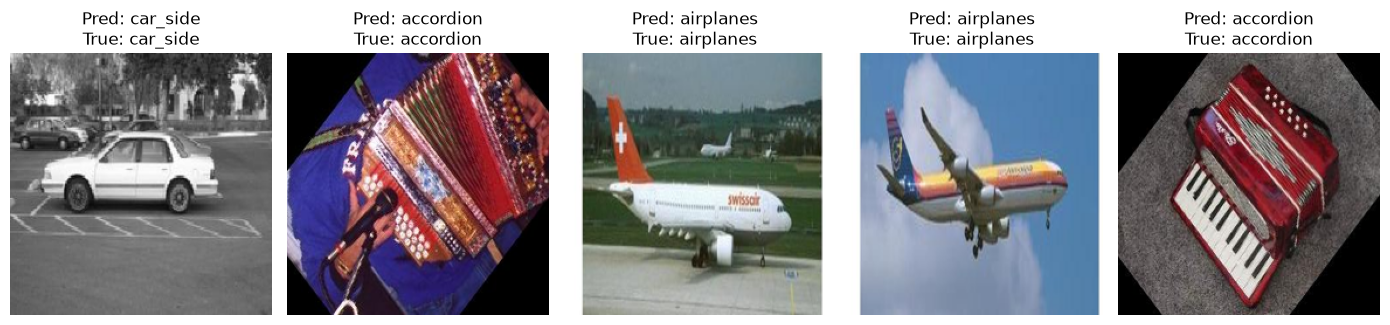

In [2]:
import matplotlib.pyplot as plt

# 11. Predict categories for five sample test images
predictions = classifier.predict(X_test_features[:5])

predicted_labels = np.argmax(predictions, axis=1)

plt.figure(figsize=(14, 5))

for i in range(5):
    plt.subplot(1, 5, i+1)
    plt.imshow(X_test[i])
    plt.title(
        f"Pred: {categories[predicted_labels[i]]}\n"
        f"True: {categories[y_test[i]]}"
    )
    plt.axis('off')

plt.tight_layout()
plt.show()
